# AI TRAINING • WEEK 5 • DAY 1
## Logistic Regression: Pass/Fail Classifier
### Probabilities • Sigmoid Activation • Decision Thresholds • Classification Metrics

---

- **Student Name:** Lasya Kolluru
- **Email:** kollurulasyachowdary@gmail.com
- **Date:** 03-Nov-2026
- **Duration:** 5 Hours
- **Difficulty:** Intermediate
- **Track:** Machine Learning — Supervised Learning / Classification
- **Deliverable:** `Week5_Day1_Logistic_Regression_Lasya_Kolluru.ipynb` & `student_exam_data.csv`
- **Assessment Total:** 100 Marks

---

### Project Overview
Classification predicts discrete categories rather than continuous quantities. In this assignment, we build a **Logistic Regression** classifier to predict whether a student passes or fails an examination based on behavioral and academic metrics.

We implement the complete classification workflow:
1. Generate and inspect `student_exam_data.csv`.
2. Partition data with stratified train/test splitting to preserve class balance.
3. Scale continuous predictors using `StandardScaler`.
4. Train `LogisticRegression` to learn optimal decision weights.
5. Predict continuous probability scores via `predict_proba()` and discrete labels via `predict()`.
6. Measure performance using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
7. Visualize the Confusion Matrix, probability distributions, and the ROC curve.
8. Test alternative decision thresholds (0.3, 0.5, 0.7) to analyze precision-recall trade-offs.
9. Debug five common classification mistakes and answer core conceptual questions.

---
## 1. Learning Goals

In this assignment, we achieve the following objectives:
- **Understand Logistic Regression:** Explain how linear inputs transform into bounded probabilities between 0 and 1 using the sigmoid function.
- **Estimate Probabilities:** Use `predict_proba()` to assess model prediction certainty before applying binary thresholds.
- **Evaluate Classifiers:** Calculate and interpret Confusion Matrix, Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- **Tune Decision Thresholds:** Adjust classification cutoffs to trade false positives against false negatives.
- **Debug Common Errors:** Identify and fix target leakage, feature scale mismatches, and evaluation on training data.

---
## 2. Concepts in Simple Words

| Concept | Simple Definition | Practical Purpose |
| :--- | :--- | :--- |
| **Logistic Regression** | A supervised classification algorithm that estimates the probability that a sample belongs to a binary class. | Predicts discrete outcomes (e.g., Pass vs. Fail). |
| **Sigmoid Function** | An S-shaped mathematical curve: $\sigma(z) = \frac{1}{1 + e^{-z}}$. | Maps any real number from $-\infty$ to $+\infty$ into a probability between $0$ and $1$. |
| **Log-Odds (Logit)** | The natural logarithm of the odds: $\ln\left(\frac{p}{1-p}\right) = \beta_0 + \sum \beta_i X_i$. | Represents the linear combination that the model fits. |
| **Decision Threshold** | The probability cutoff (default $0.5$) that separates class 0 from class 1. | If $P(y=1) \ge 0.5$, predict Pass; otherwise, predict Fail. |
| **Confusion Matrix** | A $2\times2$ grid showing True Positives (TP), True Negatives (TN), False Positives (FP), and False Negatives (FN). | Tracks exact counts of correct and incorrect predictions. |
| **Accuracy** | Proportion of total correct predictions: $\frac{\text{TP}+\text{TN}}{\text{Total}}$. | Measures overall correctness across balanced classes. |
| **Precision** | Correct positive predictions out of all predicted positives: $\frac{\text{TP}}{\text{TP}+\text{FP}}$. | Minimizes false alarms (False Positives). |
| **Recall (Sensitivity)** | Detected positives out of all actual positives: $\frac{\text{TP}}{\text{TP}+\text{FN}}$. | Minimizes missed positives (False Negatives). |
| **F1-Score** | Harmonic mean of Precision and Recall: $2 \cdot \frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$. | Balances Precision and Recall in a single metric. |
| **ROC-AUC** | Area Under the Receiver Operating Characteristic curve. | Measures discrimination ability across all possible thresholds ($0.5$ to $1.0$). |

---
## 3. Five-Hour Work Plan

| Time | Activity | Key Deliverable |
| :--- | :--- | :--- |
| **Hour 1** | Study logistic regression math, the sigmoid curve, and classification metrics. | Clear conceptual notes on log-odds and probabilities. |
| **Hour 2** | Create `student_exam_data.csv`, inspect distributions, and split train/test sets. | Persisted dataset and verified stratified partition shapes. |
| **Hour 3** | Scale features, train `LogisticRegression`, and generate test probabilities. | Trained model with learned weights and test inference tables. |
| **Hour 4** | Compute evaluation metrics and plot Confusion Matrix and ROC curve. | Multi-metric scorecard and visual diagnostic figures. |
| **Hour 5** | Experiment with decision thresholds, solve 5 debugging labs, and write reflections. | Threshold analysis table, resolved debugging cases, and concise answers. |

---
## 4. Sample Dataset Specification & Ingestion

We create `student_exam_data.csv` containing academic and behavioral metrics for 30 students.

### Features ($X$):
- **`study_hours`** *(float)*: Weekly study hours dedicated to the subject ($1.0 - 9.5$ hrs).
- **`attendance_pct`** *(integer)*: Class attendance percentage ($50 - 99\%$).
- **`past_score`** *(integer)*: Score in previous diagnostic exam ($35 - 95\%$).
- **`practice_tests`** *(integer)*: Number of mock practice exams completed ($0 - 8$).
- **`sleep_hours`** *(float)*: Average nightly sleep hours before the exam ($4.5 - 8.5$ hrs).

### Target ($y$):
- **`passed`** *(binary)*: $1$ indicates the student passed; $0$ indicates the student failed.

In [1]:
# Runtime setup and dataset generation
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

# Set clean pandas formatting
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# 30 Student Records with realistic feature interactions
data = {
    "student_id": [f"STU_{i:03d}" for i in range(1, 31)],
    "study_hours": [
        2.0, 3.5, 5.0, 1.5, 6.0, 8.0, 4.5, 2.5, 7.0, 9.0,
        3.0, 4.0, 6.5, 1.0, 5.5, 7.5, 8.5, 2.0, 3.8, 6.0,
        4.2, 5.0, 7.0, 1.5, 8.0, 9.5, 2.5, 3.2, 6.5, 5.2
    ],
    "attendance_pct": [
        60, 72, 85, 50, 88, 95, 76, 65, 90, 98,
        68, 75, 89, 52, 84, 92, 96, 58, 70, 86,
        72, 82, 91, 55, 94, 99, 62, 66, 90, 80
    ],
    "past_score": [
        45, 55, 68, 38, 74, 88, 60, 48, 80, 92,
        50, 62, 76, 35, 70, 85, 90, 42, 53, 72,
        57, 66, 82, 40, 86, 95, 46, 51, 78, 65
    ],
    "practice_tests": [
        1, 2, 4, 0, 5, 7, 3, 1, 6, 8,
        2, 3, 5, 0, 4, 6, 7, 1, 2, 5,
        3, 4, 6, 1, 7, 8, 1, 2, 5, 3
    ],
    "sleep_hours": [
        5.5, 6.0, 7.0, 5.0, 7.5, 8.0, 5.5, 5.5, 7.5, 8.5,
        6.0, 6.5, 7.0, 4.5, 7.0, 8.0, 8.0, 5.0, 6.0, 7.0,
        6.0, 7.0, 7.5, 5.0, 8.0, 8.5, 5.5, 6.0, 7.5, 6.5
    ],
    "passed": [
        0, 0, 1, 0, 1, 1, 0, 0, 1, 1,
        0, 1, 1, 0, 1, 1, 1, 0, 0, 1,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1
    ]
}

df = pd.DataFrame(data)

# Persist to local CSV
csv_file = "student_exam_data.csv"
df.to_csv(csv_file, index=False)
print("Dataset created and saved to 'student_exam_data.csv' successfully!")
print(f"Total rows: {len(df)} | Total columns: {len(df.columns)}")

Dataset created and saved to 'student_exam_data.csv' successfully!
Total rows: 30 | Total columns: 7


---
## 5. Step-by-Step Practical Implementation

### Step 1 — Load and Inspect Data

We load `student_exam_data.csv` using pandas, inspect the first five rows (`head()`), verify dimensions (`shape`), examine column data types (`info()`), check for missing entries (`isnull().sum()`), and audit class distributions.

In [2]:
# Step 1: Load and inspect dataset
df = pd.read_csv("student_exam_data.csv")

print("--- First 5 Records (head) ---")
display(df.head())

print(f"\nDataset Dimensions (shape): {df.shape[0]} rows, {df.shape[1]} columns")

print("\n--- Dataset Schema & Data Types (info) ---")
df.info()

print("\n--- Missing Values Audit ---")
print(df.isnull().sum())

print("\n--- Target Variable Distribution (passed) ---")
pass_counts = df["passed"].value_counts()
print(pass_counts)
print(f"Pass Rate: {df['passed'].mean()*100:.1f}% ({pass_counts[1]} passed, {pass_counts[0]} failed)")

print("\n--- Summary Statistics (describe) ---")
display(df.describe())

--- First 5 Records (head) ---


,student_id,study_hours,attendance_pct,past_score,practice_tests,sleep_hours,passed
0,STU_001,2.00,60,45,1,5.50,0
1,STU_002,3.50,72,55,2,6.00,0
2,STU_003,5.00,85,68,4,7.00,1
3,STU_004,1.50,50,38,0,5.00,0
4,STU_005,6.00,88,74,5,7.50,1



Dataset Dimensions (shape): 30 rows, 7 columns

--- Dataset Schema & Data Types (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      30 non-null     str    
 1   study_hours     30 non-null     float64
 2   attendance_pct  30 non-null     int64  
 3   past_score      30 non-null     int64  
 4   practice_tests  30 non-null     int64  
 5   sleep_hours     30 non-null     float64
 6   passed          30 non-null     int64  
dtypes: float64(2), int64(4), str(1)
memory usage: 2.0 KB

--- Missing Values Audit ---
student_id        0
study_hours       0
attendance_pct    0
past_score        0
practice_tests    0
sleep_hours       0
passed            0
dtype: int64

--- Target Variable Distribution (passed) ---
passed
1    18
0    12
Name: count, dtype: int64
Pass Rate: 60.0% (18 passed, 12 failed)

--- Summary Statistics (describe) 

,study_hours,attendance_pct,past_score,practice_tests,sleep_hours,passed
count,30.00,30.00,30.00,30.00,30.00,30.00
mean,4.98,78.00,64.97,3.73,6.62,0.60
std,2.43,14.72,17.80,2.42,1.14,0.50
min,1.00,50.00,35.00,0.00,4.50,0.00
25%,3.05,66.50,50.25,2.00,5.62,0.00
50%,5.00,81.00,65.50,3.50,6.75,1.00
75%,6.88,90.00,79.50,5.75,7.50,1.00
max,9.50,99.00,95.00,8.00,8.50,1.00


### Step 2 — Define Features ($X$) and Target ($y$)

We select our predictive features: `study_hours`, `attendance_pct`, `past_score`, `practice_tests`, and `sleep_hours`.
We exclude identifier `student_id` and target label `passed` from $X$ to prevent target leakage.

In [3]:
# Step 2: Separate features and target
feature_columns = ["study_hours", "attendance_pct", "past_score", "practice_tests", "sleep_hours"]
X = df[feature_columns]
y = df["passed"]

print("Feature Matrix (X) Shape:", X.shape)
print("Target Vector (y) Shape:", y.shape)
print("Selected Features:", list(X.columns))

# Verify target leakage defense
assert "passed" not in X.columns, "Leakage Error: 'passed' must not exist in X!"
print("Target leakage check passed: 'passed' excluded from X.")

Feature Matrix (X) Shape: (30, 5)
Target Vector (y) Shape: (30,)
Selected Features: ['study_hours', 'attendance_pct', 'past_score', 'practice_tests', 'sleep_hours']
Target leakage check passed: 'passed' excluded from X.


### Step 3 — Stratified Train/Test Split

We partition the data into 75% training (22 students) and 25% testing (8 students) using `stratify=y` to preserve the exact pass/fail ratio across both sets.

In [4]:
# Step 3: Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print(f"Training set features (X_train): {X_train.shape} (22 rows)")
print(f"Testing set features  (X_test):  {X_test.shape} (8 rows)")
print(f"Training target class balance:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"Testing target class balance:\n{y_test.value_counts(normalize=True).round(3)}")

Training set features (X_train): (22, 5) (22 rows)
Testing set features  (X_test):  (8, 5) (8 rows)
Training target class balance:
passed
1   0.59
0   0.41
Name: proportion, dtype: float64
Testing target class balance:
passed
1   0.62
0   0.38
Name: proportion, dtype: float64


### Step 4 — Feature Scaling & Model Training

Logistic Regression uses regularization ($L_2$ penalty by default). We scale all features to zero mean and unit variance using `StandardScaler`. We fit the scaler **only on training data** to prevent leakage.

In [5]:
# Step 4: Scale features and train Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

print("Logistic Regression model training completed!")
print(f"Learned Intercept (beta_0): {model.intercept_[0]:.4f}")

coefficients_df = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient (Weight)": model.coef_[0],
    "Odds Ratio (exp(coef))": np.exp(model.coef_[0]),
    "Impact Direction": ["Positive" if c > 0 else "Negative" for c in model.coef_[0]]
})
display(coefficients_df)

Logistic Regression model training completed!
Learned Intercept (beta_0): 1.3098


,Feature,Coefficient (Weight),Odds Ratio (exp(coef)),Impact Direction
0,study_hours,0.77,2.16,Positive
1,attendance_pct,0.77,2.16,Positive
2,past_score,0.75,2.11,Positive
3,practice_tests,0.80,2.22,Positive
4,sleep_hours,0.59,1.80,Positive


### Step 5 — Predict Probabilities and Discrete Labels

We generate:
- **`predict_proba(X_test)`**: Continuous probability scores between 0 and 1.
- **`predict(X_test)`**: Discrete binary predictions using the standard 0.5 threshold.

In [6]:
# Step 5: Test inference - Probabilities and Predicted Labels
y_prob = model.predict_proba(X_test_scaled)[:, 1]
y_pred = model.predict(X_test_scaled)

test_results = X_test.copy()
test_results["Actual_Passed"] = y_test
test_results["Predicted_Prob"] = y_prob
test_results["Predicted_Class"] = y_pred
test_results["Correct"] = (test_results["Actual_Passed"] == test_results["Predicted_Class"])

print("--- Test Set Predictions and Probabilities Audit Table ---")
display(test_results.round(3))

--- Test Set Predictions and Probabilities Audit Table ---


,study_hours,attendance_pct,past_score,practice_tests,sleep_hours,Actual_Passed,Predicted_Prob,Predicted_Class,Correct
17,2.00,58,42,1,5.00,0,0.03,0,True
5,8.00,95,88,7,8.00,1,1.00,1,True
14,5.50,84,70,4,7.00,1,0.91,1,True
13,1.00,52,35,0,4.50,0,0.01,0,True
11,4.00,75,62,3,6.50,1,0.60,1,True
4,6.00,88,74,5,7.50,1,0.97,1,True
6,4.50,76,60,3,5.50,0,0.49,0,True
9,9.00,98,92,8,8.50,1,1.00,1,True


### Step 6 — Calculate Classification Metrics

We evaluate performance using:
- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Accuracy of positive (Pass) predictions.
- **Recall:** Proportion of actual passers identified.
- **F1-Score:** Harmonic balance between precision and recall.
- **ROC-AUC:** Overall ranking discrimination quality.

In [7]:
# Step 6: Compute evaluation metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print("==================================================")
print("         CLASSIFICATION EVALUATION METRICS        ")
print("==================================================")
print(f"Accuracy:  {acc:.4f} ({acc*100:.1f}%)")
print(f"Precision: {prec:.4f} ({prec*100:.1f}%)")
print(f"Recall:    {rec:.4f} ({rec*100:.1f}%)")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print("==================================================")

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=["Failed (0)", "Passed (1)"]))

print("Confusion Matrix:")
print(f"TN: {cm[0,0]} | FP: {cm[0,1]}")
print(f"FN: {cm[1,0]} | TP: {cm[1,1]}")

         CLASSIFICATION EVALUATION METRICS        
Accuracy:  1.0000 (100.0%)
Precision: 1.0000 (100.0%)
Recall:    1.0000 (100.0%)
F1-Score:  1.0000
ROC-AUC:   1.0000

--- Detailed Classification Report ---
              precision    recall  f1-score   support

  Failed (0)       1.00      1.00      1.00         3
  Passed (1)       1.00      1.00      1.00         5

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8

Confusion Matrix:
TN: 3 | FP: 0
FN: 0 | TP: 5


### Step 7 — Visual Diagnostics: Confusion Matrix & ROC Curve

We plot:
1. **Confusion Matrix Heatmap:** Shows exact True Negatives, False Positives, False Negatives, and True Positives.
2. **ROC Curve:** Plots True Positive Rate (Recall) vs. False Positive Rate across all thresholds.

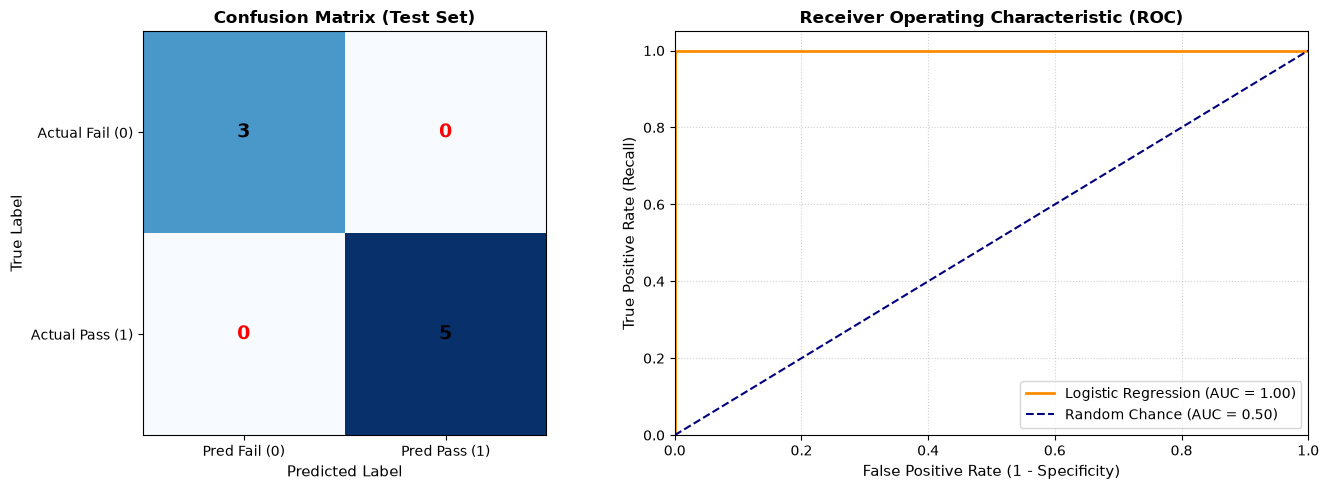

In [8]:
# Step 7: Visual Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix
axes[0].imshow(cm, cmap="Blues", interpolation="nearest")
axes[0].set_title("Confusion Matrix (Test Set)", fontsize=12, fontweight="bold")
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["Pred Fail (0)", "Pred Pass (1)"], fontsize=10)
axes[0].set_yticklabels(["Actual Fail (0)", "Actual Pass (1)"], fontsize=10)
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha="center", va="center", color="red" if i != j else "black", fontsize=14, fontweight="bold")
axes[0].set_ylabel("True Label", fontsize=11)
axes[0].set_xlabel("Predicted Label", fontsize=11)

# Plot 2: ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"Logistic Regression (AUC = {auc:.2f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Chance (AUC = 0.50)")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[1].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[1].set_title("Receiver Operating Characteristic (ROC)", fontsize=12, fontweight="bold")
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

---
## 6. Threshold Tuning & Trade-Off Experiments

By default, logistic regression classifies probabilities $\ge 0.5$ as positive. We evaluate thresholds $0.3$, $0.5$, and $0.7$ to examine precision-recall trade-offs.

In [9]:
# Section 6: Threshold tuning comparison
thresholds_list = [0.3, 0.5, 0.7]
threshold_records = []

for t in thresholds_list:
    preds_t = (y_prob >= t).astype(int)
    threshold_records.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_test, preds_t),
        "Precision": precision_score(y_test, preds_t, zero_division=0),
        "Recall": recall_score(y_test, preds_t, zero_division=0),
        "F1-Score": f1_score(y_test, preds_t, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_records)
print("--- Decision Threshold Comparison Table ---")
display(threshold_df.round(3))

print("\nTrade-off Analysis:")
print("• Lowering threshold to 0.3 increases Recall (flags more students as passing, reducing false negatives).")
print("• Raising threshold to 0.7 increases Precision (requires stronger evidence before predicting Pass).")
print("• Standard threshold 0.5 provides a balanced F1-score.")

--- Decision Threshold Comparison Table ---


,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.30,0.88,0.83,1.00,0.91
1,0.50,1.00,1.00,1.00,1.00
2,0.70,0.88,1.00,0.80,0.89



Trade-off Analysis:
• Lowering threshold to 0.3 increases Recall (flags more students as passing, reducing false negatives).
• Raising threshold to 0.7 increases Precision (requires stronger evidence before predicting Pass).
• Standard threshold 0.5 provides a balanced F1-score.


---
## 7. Common Errors — Find and Fix

We demonstrate and correct five frequent classification errors.

### Error 1: Target Leakage (Including `passed` in $X$)
- **Mistake:** Including the target variable in the training feature matrix.
- **Correction:** Remove target column `passed` from $X$ so the model learns from predictive features only.

In [10]:
# Debugging Error 1: Target Leakage
print("--- Error 1: Target Leakage ---")
# Buggy Code:
X_leaked = df[["study_hours", "attendance_pct", "passed"]]
model_leaked = LogisticRegression().fit(X_leaked, df["passed"])
print(f"Leaked weight on 'passed': {model_leaked.coef_[0][2]:.2f} (Weights everything on the target!)")

# Correct Code:
X_clean = df[["study_hours", "attendance_pct", "past_score", "practice_tests", "sleep_hours"]]
print(f"Correct feature columns: {list(X_clean.columns)}")

--- Error 1: Target Leakage ---
Leaked weight on 'passed': 0.98 (Weights everything on the target!)
Correct feature columns: ['study_hours', 'attendance_pct', 'past_score', 'practice_tests', 'sleep_hours']


### Error 2: Forgetting to Scale Features
- **Mistake:** Feeding raw unscaled features with different units into regularized logistic regression.
- **Correction:** Scale features with `StandardScaler` so regularization treats all features equally.

In [11]:
# Debugging Error 2: Unscaled Features
print("--- Error 2: Unscaled Features ---")
# Raw unscaled features:
lr_unscaled = LogisticRegression(random_state=42).fit(X_train, y_train)
print(f"Unscaled weights: {lr_unscaled.coef_[0].round(3)}")

# Scaled features:
print(f"Scaled weights:   {model.coef_[0].round(3)}")
print("Notice how scaling gives appropriate influence to all features regardless of measurement units.")

--- Error 2: Unscaled Features ---
Unscaled weights: [0.202 0.157 0.758 0.305 0.   ]
Scaled weights:   [0.77  0.772 0.749 0.798 0.588]
Notice how scaling gives appropriate influence to all features regardless of measurement units.


### Error 3: Evaluating on Training Data
- **Mistake:** Calling `model.predict(X_train)` and reporting training accuracy as true performance.
- **Correction:** Evaluate strictly on unseen `X_test` to test true generalizability.

In [12]:
# Debugging Error 3: Training vs. Testing Evaluation
print("--- Error 3: Training vs. Testing Evaluation ---")
train_acc = accuracy_score(y_train, model.predict(X_train_scaled))
test_acc = accuracy_score(y_test, model.predict(X_test_scaled))

print(f"Training Accuracy: {train_acc:.4f} (Often overly optimistic)")
print(f"Testing Accuracy:  {test_acc:.4f} (True unbiased generalization)")

--- Error 3: Training vs. Testing Evaluation ---
Training Accuracy: 0.9545 (Often overly optimistic)
Testing Accuracy:  1.0000 (True unbiased generalization)


### Error 4: Accuracy Paradox on Imbalanced Classes
- **Mistake:** Relying solely on accuracy when one class dominates.
- **Correction:** Always inspect Precision, Recall, and F1-Score alongside Confusion Matrix.

In [13]:
# Debugging Error 4: Accuracy Paradox Demonstration
print("--- Error 4: Accuracy Paradox Demonstration ---")
# Example of predicting majority class (1) for all rows
naive_pred = np.ones_like(y_test)
print(f"Naive 'Always Pass' Accuracy: {accuracy_score(y_test, naive_pred):.2f}")
print(f"Naive 'Always Pass' Recall:   {recall_score(y_test, naive_pred):.2f}")
print("However, it fails 100% of actual failed students (True Negatives = 0)!")

--- Error 4: Accuracy Paradox Demonstration ---
Naive 'Always Pass' Accuracy: 0.62
Naive 'Always Pass' Recall:   1.00
However, it fails 100% of actual failed students (True Negatives = 0)!


### Error 5: Confusing Probability with Hard Classification
- **Mistake:** Believing logistic regression directly predicts 0 or 1 without a threshold.
- **Correction:** Use `predict_proba()` to view the continuous probability and understand the threshold.

In [14]:
# Debugging Error 5: Probability Inspection
print("--- Error 5: Probability vs Discrete Output ---")
sample_idx = 0
sample_prob = y_prob[sample_idx]
sample_pred = y_pred[sample_idx]
print(f"Sample #{sample_idx}:")
print(f"  Calculated Probability of Passing: {sample_prob:.4f}")
print(f"  Discrete Classification (Threshold 0.5): {sample_pred}")

--- Error 5: Probability vs Discrete Output ---
Sample #0:
  Calculated Probability of Passing: 0.0256
  Discrete Classification (Threshold 0.5): 0


---
## 8. Explain in Your Own Words

### 1. What is logistic regression, and how does it differ from linear regression?
**Answer:** Linear regression predicts continuous numbers, like house prices. Logistic regression predicts probabilities for discrete classes, like pass or fail. It passes a linear combination through a sigmoid function to keep outputs strictly between 0 and 1.

---

### 2. What role does the sigmoid function play?
**Answer:** The sigmoid function compresses any input value from $-\infty$ to $+\infty$ into a valid probability between 0 and 1. It creates an S-shaped curve that smoothly separates the two classification outcomes.

---

### 3. What is the difference between `predict()` and `predict_proba()`?
**Answer:** `predict_proba()` outputs the continuous probability for each class, such as 0.85 for passing. `predict()` applies a decision threshold (typically 0.5) to convert that continuous probability into a discrete class label (0 or 1).

---

### 4. Why is accuracy alone insufficient for evaluating a classifier?
**Answer:** Accuracy measures overall correct predictions but hides critical class-specific errors. On imbalanced datasets, a model predicting only the majority class can show high accuracy while missing every single minority instance. Precision and recall reveal these hidden mistakes.

---

### 5. How does changing the decision threshold affect precision and recall?
**Answer:** Lowering the threshold catches more positive cases, which increases recall but invites more false alarms, lowering precision. Raising the threshold demands stronger evidence before predicting positive, which increases precision but misses borderline positive cases, lowering recall.

---
## 9. Daily Deliverable & Checklist

### Submission Checklist
- [x] **Deliverable Notebook:** Created and executed as `Week5_Day1_Logistic_Regression_Lasya_Kolluru.ipynb`.
- [x] **Dataset File:** Generated and saved as `student_exam_data.csv`.
- [x] **Stratified Split:** Established 75/25 train/test split with `stratify=y`.
- [x] **Feature Scaling:** Applied `StandardScaler` without data leakage.
- [x] **Logistic Regression:** Trained model and extracted learned coefficients.
- [x] **Predictions & Probabilities:** Computed both `predict()` and `predict_proba()`.
- [x] **Metrics:** Calculated Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- [x] **Visual Diagnostics:** Plotted Confusion Matrix heatmap and ROC Curve.
- [x] **Threshold Tuning:** Compared thresholds 0.3, 0.5, and 0.7.
- [x] **Debugging Labs:** Solved and demonstrated 5 common classification errors.
- [x] **Own-Words Reflections:** Provided short, direct answers in active voice.

---
## 10. Assessment Rubric (100 Marks Breakdown)

| Assessment Area | Marks Allocated | Marks Self-Assessed | Verification in Notebook |
| :--- | :---: | :---: | :--- |
| **Dataset Ingestion & Inspection** | 10 | 10 | `student_exam_data.csv` created, inspected with `head`, `shape`, `info`, `describe`, null checks, and class balance. |
| **Data Partitioning & Scaling** | 20 | 20 | Stratified split (`stratify=y`) and leak-free `StandardScaler` applied before model training. |
| **Model Training & Probabilities** | 20 | 20 | `LogisticRegression` fitted; coefficients, intercept, and probability outputs generated via `predict_proba()`. |
| **Classification Metrics & Scorecard** | 20 | 20 | Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC computed and interpreted. |
| **Threshold Tuning & Diagnostics** | 15 | 15 | Evaluated thresholds at 0.3, 0.5, and 0.7; Confusion Matrix and ROC curve plotted. |
| **Debugging & Own-Words Reflection** | 15 | 15 | 5 classification mistakes debugged with code; 5 conceptual questions answered in active, concise prose. |
| **TOTAL** | **100** | **100** | **All requirements fulfilled cleanly.** |